# **TP1 | Chiffrements fondamentaux**

*Compétences de programmation :*
- manipuler la structure de données `bytes` en Python
- appliquer un masque XOR

*Compétences cryptographiques :*
- visualiser un résultat de chiffrement sur une image en noir et blanc
- découvrir le risque le plus courant en cryptographie : la réutilisation d'une clé de chiffrement

***Introduction***

La cryptographie étudie l'échange de messages de manière sécurisée. Plus spécifiquement, elle s'intéresse à la **confidentialité** : le message ne doit pas être lisible par un tiers.

Pour cela, on utilise des **chiffrements** : des transformations du message original (le **texte clair**) en un message codé (le **texte chiffré**). Le chiffrement est réversible : il existe une transformation inverse permettant de retrouver le texte clair à partir du texte chiffré.

Dans ce TP, ce concept est introduit avec le chiffre de César. On visualise ensuite un exemple de chiffrement par masque sur une image en noir et blanc, inspiré par un [article de Cryptosmith](https://cryptosmith.com/2008/05/31/stream-reuse/).

## 1.1. Chiffre de César

Un des plus anciens algorithmes de chiffrements est le [chiffre de César](https://fr.wikipedia.org/wiki/Chiffrement_par_d%C3%A9calage). Il consiste à décaler chaque lettre d'un certain nombre de positions dans l'alphabet. Par exemple, avec un décalage de 3, A devient D, B devient E, etc.

Aujourd'hui, ce chiffrement est très facile à casser, même avec des outils gratuits en ligne comme [dCode](https://www.dcode.fr/chiffre-cesar).

**TODO**  
1. Quel est le type de `ciphered_data` ci-dessous? Que vaut `cipher_data[0]`?
2. Décrypter le message codé `cipher_text`. De quelle œuvre est-ce l'ouverture?
3. Vérifier que `cesar.encrypt(cesar.decrypt(text, key), key)` renvoie bien `text` pour différentes clés.

*décrypter*: Retrouver le sens clair d'un message chiffré en écriture secrète, sans connaître la clef ayant servi à le transcrire. (définition Larousse)

In [1]:
import cesar

cipher_text = "Iutzk-suo, Sayk, r'nussk gad sorrk zuaxy"
cipher_data = cipher_text.encode(encoding="utf-8")
# TODO
# Quel est le type de `ciphered_data` ci-dessous? Que vaut `cipher_data[0]`?
print(type(cipher_data), cipher_data[0])

# C'est un type `bytes` qui contient des octets (des nombres entiers entre 0 et 255 inclus)
# cipher_data[0] == 73 == 0x49, qui tient bien sur un octet

<class 'bytes'> 73


In [2]:
# TODO
# Décrypter le message codé. De quelle œuvre est-ce l'ouverture?

for key in range(4,8):
    deciph_data = cesar.decrypt(cipher_data, key)
    deciph_text = deciph_data.decode()
    print("  " if key != 6 else "> ", end="")  # hand-picked
    print(f"Clé {cesar.key_to_char(key)}:", deciph_text)

# Ouverture de L'Odyssée (traduction Hélène Tronc, éditions Gallimard)

  Clé E: Eqpvg-oqk, Owug, n'jqoog cwz oknng vqwtu
  Clé F: Dpouf-npj, Nvtf, m'ipnnf bvy njmmf upvst
> Clé G: Conte-moi, Muse, l'homme aux mille tours
  Clé H: Bnmsd-lnh, Ltrd, k'gnlld ztw lhkkd sntqr


In [3]:
# TODO
# Vérifier que `cesar.encrypt(cesar.decrypt(data, key), key)` renvoie bien `data` pour différentes clés.

failed_deciph = []

for key in range(26):
    deciph_data = cesar.decrypt(cipher_data, key)
    reciph_data = cesar.encrypt(deciph_data, key)
    if reciph_data != cipher_data:
        failed_deciph.append(cesar.key_to_char(key))

if failed_deciph == []:
    print("All reciphers matched.")
else:
    print("!! Reciphers with", ",".join(failed_deciph), "failed.")

All reciphers matched.


## 1.2. Masque jetable

Pour éviter que ce chiffrement soit trop facile à casser, on peut utiliser un **masque jetable** (ou *one-time pad* en anglais). Il s'agit d'une clé de chiffrement aléatoire, de la même longueur que le message à chiffrer.

Pour des données informatiques génériques, l'alphabet n'est pas composé de 26 lettres, mais de bits ! On va donc considérer des images avec 1 bit par pixel, en noir et blanc (de valeurs 0 et 1 respectivement).

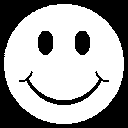

In [4]:
from PIL import Image

smiley = Image.open("smiley.gif")
smiley

### 1.2.a. Validation du binaire

**TODO**  
À l'aide de la méthode `Image.get_flattened_data` et de la structure `set` (qui ne garde que les éléments uniques), vérifier que les pixels de l'image `smiley.gif` ne prennent que les valeurs 0 ou 1.

In [5]:
# TODO
# À l'aide de la méthode `Image.get_flattened_data` et de la structure `set` qui ne garde que les éléments uniques, 
# vérifier que les pixels de l'image `smiley.gif` ne prennent que les valeurs 0 ou 1.
smiley_data = smiley.get_flattened_data()
set(smiley_data) <= {0, 1}  # <= est l'inclusion

True

### 1.2.b. Opération XOR

Le XOR est un opérateur binaire associatif et commutatif (comme AND et OR) défini par la table de vérité suivante :

| $\oplus$ | 0 | 1 |
|:--------:|:-:|:-:|
| **0**    | 0 | 1 |
| **1**    | 1 | 0 |

Autrement dit, pour un bit $b$, $b \oplus 0 = b$ et $b \oplus 1 = \neg b.$ On a aussi $b \oplus b = 0$.

En Python, cet opérateur est implémenté sur les `int` avec le symbole `^`.

**TODO**
- Grâce à la méthode `Image.putdata` et la fonction `xor`, chiffrer l'image `smiley.gif` avec la clé `key.gif`.
- Analyser le résultat :
    - Que remarque-t-on dans les bandes horizontales où la clé est noire (0) ou blanche (1) ? Est-ce le comportement attendu?
    - Dans les bandes où les pixels de la clé sont aléatoires, peut-on deviner l'image originale?

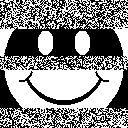

In [6]:
def xor(a: bytes, b: bytes):
    return bytes(x ^ y for x, y in zip(a, b))


# initialise une nouvelle image avec les même paramètres (taille, palette, etc) que `smiley.gif`
cipher = smiley.copy()

# TODO
# Lire la clé, puis grâce à la méthode `Image.putdata` et la fonction `xor`,
# chiffrer l'image `smiley.gif` avec la clé `key.
key = Image.open("key.gif")
key_data = key.get_flattened_data()
cipher_data = xor(smiley_data, key_data)
cipher.putdata(cipher_data)
cipher

# TODO
# Analyser le résultat.
# La clé est composée de pixels aléatoires, mis à part deux bandes horizontales.
# La bande blanche (valeurs 1) a inversé les pixels du smiley : le noir est devenu blanc, et réciproquement.
# La bande noire (valeurs 0) n'a pas modifié les pixels.
# C'est bien le comportement attendu étant donné les identités b^1 = !b et b^0 = b.
# Dans les bandes aléatoires, on ne distingue plus du tout l'image originale.

### 1.2.c. Appliquer le masque deux fois

**TODO**  
Chiffrer à nouveau l'image chiffrée avec la même clé. Que remarque-t-on? Est-ce le comportement attendu?

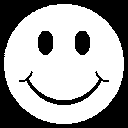

In [7]:
# TODO
# Chiffrer à nouveau l'image chiffrée avec la même clé. Que remarque-t-on? 
# Est-ce le comportement attendu?

reciph = smiley.copy()
reciph_data = xor(cipher_data, key_data)
reciph.putdata(reciph_data)
reciph

# On retrouve l'image d'origine. C'est logique : appliquer le masque deux fois revient à calculer 
# (b ^ k) ^ k = b ^ (k ^ k) = b ^ 0 = b

## 1.3. Réutilisation de masque XOR

Attention à ne jamais réutiliser une clé XOR !

Dans les fichiers `cipher1.gif` ($c_1$) et `cipher2.gif` ($c_2$), nous avons deux images qui ont été XOR-ées avec le même masque.

**TODO**  
Que se voit-on si on calcule $c_1 \oplus c_2$ ?

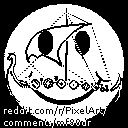

In [8]:
# TODO
# Que se voit-on si on calcule le XOR des deux images chiffrées ?

cipher1 = Image.open("cipher1.gif")
cipher2 = Image.open("cipher2.gif")

cipher1_data = cipher1.get_flattened_data()
cipher2_data = cipher2.get_flattened_data()

merged = cipher1.copy()
merged_data = xor(cipher1_data, cipher2_data)
merged.putdata(merged_data)
merged

## 1.4. Bonus : Énigme

Le bonus permet de :
- lire un fichier
- travailler la «[pensée latérale](https://fr.wikipedia.org/wiki/Pens%C3%A9e_lat%C3%A9rale)»
- utiliser un chiffrement de Vigenère

**TODO**  
1. Déchiffrer (en XOR) le document textuel `text.enc` avec la clé `key.bin` et l'afficher en tant que texte avec la méthode `bytes.decode`.
2. À l'aide des éléments déchiffrés dans les parties précédentes, déduire le nom de ce que ce texte représente (en 5 lettres). 
3. Utiliser ce nom comme clé pour le texte `STEZDA` dans un [chiffrement de Vigenère](https://www.dcode.fr/chiffre-vigenere) pour me communiquer le résultat. Le résultat est cohérent avec la thématique des autres indices.

In [9]:
with open("text.enc", "rb") as f:
    data = f.read()

# TODO
# Lire la clé de la même manière, puis déchiffrer les données.
# Afficher le texte ainsi obtenu (ou le sauvegarder dans un fichier).
# En déduire la suite de l'énigme.
with open("key.bin", "rb") as f:
    key = f.read()

print(xor(data, key).decode())

         __
        /  \
       / ..|\
      (_\  |_)
      /  \@' 
     /     \
_   /  `   |
\\/  \  | _\
 \   /_ || \\_
  \____)|_) \_)


Si besoin d'aide supplémentaire, m'appeler pour que je vous donne un indice :
```hex
a19878d8fd63b462f5b43f0350c8644f062668f8691f3b2f42d611073ab2c
05fe6d18056b21f2e44c3bb5940771c353c66153724887318bc47ba6b7dca
7de59cb1c48dd871dc3ba696c73ab15be365a47adb16e7acf25d87a9c1345
4e4001bce2a8f9ccea9c0ddcc32bf010630d55ab4aa48541ec2a646630577
9d5bd85cda169bfd0398e090407cbf
```

In [ ]:
secretkey = bytes.fromhex("")
...

'f̴r̶.̷w̸i̴k̸i̵p̶e̵d̵i̶a̸.̴o̴r̴g̶/̷w̶i̷k̶i̴/̴A̵r̷g̸o̴s̷_̴(̴c̷h̵i̵e̴n̷_̷d̵%̶2̴7̸U̶l̶y̶s̴s̷e̵)/'